# PREVAIL · Two approaches to the same readout

**Start with the side-by-side results in the table below.** The live figures are in the final section. The first figure compares MACE-4 and MACE-3 at interim and at full information. The second explains the percentage-point differences by swapping one assumption at a time. The third tests the event-rate range and early stopping rule. The figures use the saved outputs of the common calculation in the final section, **Compare both forecasts**. After editing inputs, run all cells to regenerate the live results at the end. The opening table is a snapshot of the supplied defaults.

| Modeling decision | Memo-based scenario approach | Independent evidence approach |
|---|---|---|
| Treatment effect | Analyst HR scenarios with explicit probabilities. The weighted distribution is our implementation of uncertainty around the memo. | Continuous uncertainty from endpoint-matched REVEAL estimates, lipid scaling and transport error, with a direct obicetrapib update for MACE-4. |
| Information at each look | Inferred MACE-4 targets. Separate interim and full MACE-3 count ratios. | Expected events at two calendar cutoffs under the selected enrollment curve and rate. Hard-event ratio from REVEAL. |
| Test used for comparison | Both forecasts use the same favorable-tail group-sequential calculation, alpha budget and selected spending family. | Same. The nominal boundary can vary when the information fraction changes. |
| What each percentage means | Probability of a favorable endpoint crossing across the specified HR distribution. | Same. “Full” imagines collection of the full dataset, including trials that would already have crossed early. |

**Learning route.** Use Lessons 1–6 for patient examples, rates, information and statistical tests. Lessons 7–9 work through scenario-weighted power, dependence and stopping. The published-evidence section derives an HR distribution from external trials. The final comparison runs both sets of inputs through one calculator. The memo provides no joint prior linking all MACE-3 worlds with all MACE-4 worlds. For that reason, the headline comparisons show each endpoint's marginal chance. The earlier joint-screen examples state their pairing assumptions explicitly.


| Endpoint and method | Interim | Full if collected |
|---|---:|---:|
| MACE-4 · Memo scenarios | 42.1% | 65.2% |
| MACE-4 · Published evidence | 52.1% | 67.8% |
| MACE-3 · Memo scenarios | 14.2% | 38.9% |
| MACE-3 · Published evidence | 36.1% | 51.0% |

[Jump to the live comparison and plots](#Compare-both-forecasts)

# Will PREVAIL meet its cardiovascular endpoint?
### A first course in trial forecasting with Python · Public information through November 24, 2026

**Independent forecast.** Run All, then open “Independent forecast” for a published-data model of both endpoints. Lessons 1–11 teach the calculations and retain the earlier memo as a comparison.

**Two questions, three denominators.** What is the chance of a positive MACE-4 result if all planned events are collected? What is the chance it already crosses at interim? If the trial continues, what is the chance it subsequently crosses at final? The same simulated trial supplies both looks. Lesson 8 estimates MACE-3 at both looks and shows how a requirement for corroboration changes the forecast.

**How to use this.** Open in Jupyter or VS Code, select Python 3, and run cells from the top with Shift+Enter. In a fresh environment install Python packages with `%pip install numpy pandas scipy matplotlib` in a notebook cell. All tables and figures have saved outputs. Everything runs offline after installation. Read Lessons 1–5 once before editing the assumptions. Then change one number at a time in Lessons 4–8 and run all cells again. The attached analyst memo is abbreviated **memo** below. All patient examples are fictional.

## 1 · What is actually being counted?

Imagine a participant who undergoes elective coronary revascularization at month 8 and has an ischemic stroke at month 19. Their first amended PREVAIL **MACE-4** is at month 8. For a three-component outcome excluding revascularization, their first qualifying event is at month 19. A treatment can reduce one type of event more than another. Expanding a composite therefore changes both the event count and the effect we expect to measure.

| Question | PREVAIL evidence or modeling choice |
|---|---|
| Who and what? | 9,541 people with established ASCVD, randomized 1:1 to daily oral obicetrapib 10 mg or placebo on background maximally tolerated lipid-lowering therapy. NAMS May update slide 5. |
| Primary outcome | Time to first coronary heart disease death, nonfatal MI, fatal or nonfatal ischemic stroke, or coronary revascularization. NAMS November deck slide 27. The older urgent/non-elective definition was broadened to total coronary revascularization. The November slide describing the blinded year-1 curve uses shorter stroke wording. Use the explicit primary endpoint on slide 27. |
| What changed? | The endpoint schematic reproduced on memo p. 2 shows the narrower death/stroke definitions and wider revascularization definition. Count each patient once for the composite. “Total revascularization” describes which procedures qualify. |
| What has been observed? | NAMS reported blinded year-1 MACE accrual similar to BROADWAY and slower than expected accrual between years 1 and 2. Identifying and adjudicating events can change the preliminary figures. The sponsor plot pools treatment arms. |
| Event counts and follow-up | The sponsor slide reproduced on memo p. 3 says about 950 originally, >950 at interim, and >>950 at final. It gives approximate median/minimum follow-up of 3.5/2.5 years at interim and 4.5/3.5 years at final. These are timeline estimates. The analysis below treats exact counts, alpha, and stopping criteria as unknown. |
| Timing and action | November 4 guidance targets the interim event trigger in Q4 2026 and its outcome in Q1 2027. The extension slide projects year-end 2027 for full analysis. The independent DSMB can recommend efficacy stopping, futility, or continuation using prespecified criteria and discretion. A statistical threshold crossing and a public stop announcement are distinct outcomes. |

**What ORION-4 can teach us.** The attached design paper describes inclisiran, about 15,000 planned participants, a projected placebo event rate of 2.7% annually, and about a quarter relative benefit. Its full follow-up plan requires both 1,700 unrefuted first events and median follow-up of at least five years. The supplement (mmc5, Table 2) gives 16,124 randomized. Its design-power example uses two-sided 0.01; read the SAP separately for its testing sequence. ORION-4's outcome definitions (mmc4, §§1 and 4) specify **urgent** coronary revascularization and include undetermined stroke with ischemic stroke under its rules. Its SAP (mmc2, §§4 and 8) uses intention-to-treat first-event log-rank comparisons. Its interim benefit look requires at least 1,360 events and four years median follow-up. Early-stop guidance generally seeks ≥3 standard deviations on **both the primary and cardiovascular mortality**, subgroup consistency and reassuring safety. After an early-stop recommendation the SAP specifies two-sided p<0.001 to formally declare significance. Three standard deviations corresponds to about 0.0027 two-sided. These are different steps. Borrow the logic of a corroborating endpoint and a demanding early boundary. PREVAIL's exact DSMB charter remains an uncertainty.

## 2 · From four people to a statistical test

**Risk** is the proportion experiencing an outcome by a stated time. **Hazard** is the instantaneous rate among those still event-free. At constant hazard 0.05/year, one-year risk is 1−exp(−0.05), or 4.88%. **HR** divides the treatment hazard by the placebo hazard. An HR of 0.85 means a 15% lower instantaneous hazard. **Censoring** means we know the patient was event-free only up to the last observation. An unrelated death permanently prevents future MACE and can be modeled as a competing event.

Run the cell. Read a line beginning with # as an explanation. A list stores several values, a dictionary attaches names to values, and a loop repeats the indented lines. Each row below is one person. At month 1, two of four people at risk are treated. Under equal hazards we expect half of that month's single event on treatment. At month 3, one of two is treated. Again we expect half an event. We observe zero treated events. How unusual is that?

In [1]:
import math
import numpy as np                     # Arrays: arithmetic on many numbers at once.
import pandas as pd                    # Tables with labeled rows and columns.
import matplotlib.pyplot as plt         # Draw the calendar and sensitivity charts.
from scipy.stats import norm            # Standard Normal distribution, mean 0, variance 1.
from scipy.integrate import quad        # Numerically sum probabilities over an interval.
from scipy.optimize import brentq       # Find an input that makes a function equal zero.

## Edit your assumptions here

Run the imports above, edit the next cell, then choose **Run All**. The entries below are forecasts unless specifically identified as study facts. MACE-3 here means the first CHD death, nonfatal MI, or fatal/nonfatal ischemic stroke. A coronary procedure counts for MACE-4. The same person can later have their first MACE-3.

| Input | Meaning and reason to change it |
|---|---|
| RATE_GRID and RATE_BASIS | Your 3.7–4.3 first MACE-4 events per 100 at-risk person-years, centered at 4.0. Select placebo if based on a control arm or pooled if based on blinded trial-wide incidence. Enter 4.0 to mean 0.040/year. A one-year cumulative incidence requires a different conversion. |
| LATE_RATE_MULTIPLIER | Default 1.0 applies the range throughout follow-up. Set 0.8 to model a 20% lower control hazard after year one. The rate grid then anchors the first year. |
| EARLY_HR and LATE_HR | Relative hazards in the first year and subsequent years. They affect both accrual and the expected effect at each cutoff. The fixed-information scenario table separately uses cumulative HRs. |
| FINAL_EVENTS and INTERIM_FRACTION | Determine the information available at each MACE-4 look. The exact counts are estimates. A published target would supersede them. |
| HARD_RATIO_IA and HARD_RATIO_FULL | Ratios of expected first MACE-3 counts to first MACE-4 counts at the same calendar cut. The interim ratio is anchored to the memo. The full ratio is an assumption. Use separately observed counts if available. |
| HARD_CASES | Each row specifies a name, weight, cumulative interim MACE-3 HR and cumulative full MACE-3 HR. Equal weights make a transparent illustration. Set them to your beliefs or report the rows separately. |
| ENDPOINT_CORR | Dependence of the two endpoint score increments. Shared deaths, strokes and MIs suggest positive dependence. Known event counts alone do not identify it. |
| TWO_SIDED_ALPHA, SPENDING, CUSTOM_SHARE | Change the total error budget and the timing of its use. A stricter interim boundary can lower early power substantially. MACE-3 thresholds model a hypothetical corroboration rule. |
| M4_WORLDS | Each row supplies a prior weight and cumulative MACE-4 HRs at interim and full. Change weights for a different PoS or the HRs for a different estimate of biological benefit. |
| Enrollment, competing exits and calendar deadline | N is the randomized study size. Shape varies flat versus rising enrollment over the specified months. Loss and nonqualifying death shorten observable follow-up. The deadline tests what could be detected with the events available on a particular date. |

In [2]:
# EDIT percentages as decimals except for the explicitly labeled rate per 100 years.
RATE_GRID = [3.7, 4.0, 4.3]
RATE_BASIS = "placebo"              # "pooled" approximates an equal-risk-set arm blend.
LATE_RATE_MULTIPLIER = 1.0
EARLY_HR, LATE_HR = 0.90, 0.90 * 0.92
N = 9541
enroll_months = 26                  # Starting March 2022.
exit_rate = -math.log(0.90) / 4.5  # 10% cumulative competing/loss risk over 4.5 years in isolation.
DEADLINE = "2027-12-01"            # Month label includes accrual through the end of December.
FINAL_EVENTS = 1592
INTERIM_FRACTION = 0.70
TWO_SIDED_ALPHA = 0.05
SPENDING = "OBF"                   # Also "strict", "3 SD", "Pocock", "custom".
CUSTOM_SHARE = 0.10
HARD_RATIO_IA = 834 / 1114
HARD_RATIO_FULL = 0.75
ENDPOINT_CORR = 0.80
# Paired with memo-like MACE-4 HRs below; these three-point trajectories are sensitivities.
PAIR_HR4 = (0.86, 0.85)
HARD_CASES = [("Weaker hard outcomes", 0.50, 1.00, 0.98),
              ("More favorable hard outcomes", 0.50, 0.88, 0.86)]
M4_WORLDS = [("Strong benefit", 0.20, 0.80, 0.79), ("Memo-like", 0.40, 0.86, 0.85),
             ("Weak benefit", 0.25, 0.93, 0.92), ("Null", 0.15, 1.00, 1.00)]
assert RATE_BASIS in ("placebo", "pooled") and all(rate > 0 for rate in RATE_GRID)
assert 0 < HARD_RATIO_IA <= 1 and 0 < HARD_RATIO_FULL <= 1 and abs(ENDPOINT_CORR) < 1
assert all(w >= 0 and min(a,b)>0 for _,w,a,b in HARD_CASES)
assert np.isclose(sum(w for _,w,_,_ in HARD_CASES), 1)

### Work through the four patients

In [3]:
# Each tuple holds (treated?, months observed, ended in MACE?).
people = [(False, 1, True), (False, 3, True),
          (True, 2, False), (True, 4, False)]
score = 0.0
variance = 0.0
for month in [1, 3]:
    # A patient observed through this month belongs to its risk set.
    at_risk = [person for person in people if person[1] >= month]
    treated_share = sum(person[0] for person in at_risk) / len(at_risk)
    treated_events = sum(treated and time == month and event
                         for treated, time, event in people)
    # One event each time. Expected minus observed gives a positive score for benefit.
    score += treated_share - treated_events
    variance += treated_share * (1 - treated_share)
    print(month, "months:", len(at_risk), "at risk;", treated_share, "expected;", treated_events, "observed")
z_toy = score / math.sqrt(variance)
print(f"Z = {z_toy:.3f}; approximate two-sided p = {2 * norm.sf(abs(z_toy)):.3f}")

1 months: 4 at risk; 0.5 expected; 0 observed
3 months: 2 at risk; 0.5 expected; 0 observed
Z = 1.414; approximate two-sided p = 0.157


The numerator is 1 event. The null variance is 0.25+0.25=0.50. A **Z score** measures the gap in units of its standard deviation, so 1/√0.50=1.414. A **p-value** asks how often a difference at least this extreme would arise under equal hazards. The toy example gives 0.157 using a large-sample approximation. A real CVOT has hundreds of events. In a balanced risk set each event contributes roughly 0.25 information units. This leads to the approximation $SE(\log HR)\approx 2/\sqrt D$, where D is the **pooled number of first events**. A Cox regression estimates a log hazard ratio by comparing treatment membership among those who have events with the treatment composition of the risk sets. The log-rank score tests whether the treatment coefficient is zero. We use its large-sample information approximation to forecast before individual PREVAIL data are available.

## 3 · Rebuild the memo's event-target table

Imagine repeating an equally large trial many times. **Power** is the fraction that would pass a fixed rule if a specific true HR held every time. Alpha is the chance of a false rejection under the null allowed by the testing procedure. For a two-sided 5% final test the favorable tail uses 2.5% and its cutoff is Z=1.96. For 90% power the trial's expected favorable Z needs another 1.282 standard deviations above that cutoff. Solve $-\log(HR)\sqrt{D/4}=1.96+1.282$. Smaller effects require more events because the distance to the null on the log scale gets smaller.

In [4]:
def events_needed(hr, power, two_sided_alpha):
    # isf(0.025) locates the point with 2.5% of a Normal curve above it.
    critical_z = norm.isf(two_sided_alpha / 2)
    # ppf(0.90) locates the point with 90% of the curve below it.
    power_margin = norm.ppf(power)
    log_effect = abs(math.log(hr))
    raw_events = 4 * ((critical_z + power_margin) / log_effect) ** 2
    return math.ceil(raw_events)        # Round upward to a whole person with an event.

rows = []
for hr in [0.80, 0.85]:
    for alpha in [0.01, 0.05]:
        rows.append([hr, alpha, events_needed(hr, 0.80, alpha), events_needed(hr, 0.90, alpha)])
pd.DataFrame(rows, columns=["True HR", "Two-sided alpha", "Events for 80%", "Events for 90%"])

True HR,Two-sided alpha,Events for 80%,Events for 90%
0.80,0.01,939,1196
0.80,0.05,631,845
0.85,0.01,1769,2254
0.85,0.05,1189,1592


**Check against p. 3.** HR 0.85 and alpha 0.05 give about 1,592 events for 90% power. Rounding in the memo can differ by one event. That arithmetic reconstructs a plausible design. It cannot identify which alpha the sponsor prespecified. Designing for power at p<0.01 can coexist with a different formal success threshold. A 15% **design alternative** is a value used to size a trial. It is a separate input from the assumed true HR when forecasting.

## 4 · Where might the treatment effect come from?

The memo cites the lipid-lowering literature as a biological anchor. If a 1 mmol/L LDL-C reduction is associated with a long-run rate ratio of 0.78, then a 0.75 mmol/L reduction gives $0.78^{0.75}$, about 0.83. This extrapolates from other therapies, endpoints and exposure durations. BROADWAY's exploratory four-point estimate of 0.79 had a wide 95% CI of 0.54–1.15 (memo p. 13, NAMS May presentation). The randomized counts there are uneven because BROADWAY used 2:1 allocation. PREVAIL uses 1:1. Earlier treatment or background therapy and a different component mix can change the effect. An early lipid reduction is measured with greater precision than its translation into first CV events.

**Can you extract HR from the blinded curve?** The memo reads approximately 4.55% from the sponsor figure. In this teaching calculation use this as pooled year-1 risk and assume complete follow-up with equal allocation. Then treated risk = twice pooled risk minus assumed placebo risk. Convert both risks to constant hazards using −log(1−risk). In real data, pooled Kaplan–Meier, competing risks and differential follow-up require more care.

In [5]:
pooled_year1 = 0.0455                 # Approximate reading from the memo, not an exact release.
print("Illustrative LDL-derived long-run rate ratio:", round(0.78 ** 0.75, 3))
implied = []
for placebo_risk in [0.045, 0.048, 0.050, 0.052]:
    treated_risk = 2 * pooled_year1 - placebo_risk
    placebo_hazard = -math.log1p(-placebo_risk)
    treatment_hazard = -math.log1p(-treated_risk)
    implied.append([placebo_risk, treated_risk, treatment_hazard / placebo_hazard])
pd.DataFrame(implied, columns=["Assumed placebo risk", "Implied treated risk", "Implied year-1 HR"])

Illustrative LDL-derived long-run rate ratio: 0.83


Assumed placebo risk,Implied treated risk,Implied year-1 HR
0.045,0.046,1.022754
0.048,0.043,0.893508
0.050,0.041,0.816173
0.052,0.039,0.744949


Read across rows. The *same* blinded percentage can accommodate little benefit or a large benefit. Using a matched external placebo arm is a substantive assumption. A blinded slowdown in year two can follow from falling background risk, delayed benefit, differential observation, or a combination. The memo's 0–5 trial similarity scores, its 4.9→3.9 benchmark rates per 100 person-years and its 0.92 later-to-earlier HR multiplier are analyst choices. Reproducing their exact derivation would need the digitized curves, adjustment rules and weights.

**How does revascularization change the HR?** Imagine 75% of first-event control hazard comes from the three hard outcomes and 25% from revascularization. At a single time, the composite HR is the weighted average of the component HRs in the relevant event-free population. This is a thought experiment about cause-specific hazards. Using a time-to-first MACE-3 HR among everyone, including people who already had revascularization, as that hard-component HR is an approximation.

In [6]:
hard_share = 0.75
mix_rows = []
for hard_hr in [0.86, 0.98]:
    for procedure_hr in [0.70, 0.85, 1.00]:
        composite_hr = hard_share * hard_hr + (1 - hard_share) * procedure_hr
        mix_rows.append([hard_hr, procedure_hr, composite_hr])
pd.DataFrame(mix_rows, columns=["Hard component HR", "Revascularization HR", "Composite HR"])

Hard component HR,Revascularization HR,Composite HR
0.86,0.70,0.8200
0.86,0.85,0.8575
0.86,1.00,0.8950
0.98,0.70,0.9100
0.98,0.85,0.9475
0.98,1.00,0.9850


## 5 · When can the trial reach a look?

Enrollment and events have two clocks. Someone entering in month 18 with an MI 10 months later contributes an event at calendar month 28, at follow-up month 10. The code models monthly enrollment over March 2022–April 2024, an approximation to dates in the memo. Edit the two placebo hazards, the HRs, and the enrollment shape. The rate in an interval is conditional on being event-free at its start. For instance, a control hazard of 0.049 per year equals 4.9 events per 100 at-risk person-years. These inputs refer to the qualifying composite. A hazard for unrelated death or independent follow-up loss removes patients from the observable risk set. Treatment discontinuation alone does not end ITT follow-up.

At each small monthly step, multiply the probability of entering the step still at risk by the probability of experiencing MACE in that step. With MACE hazard $m$, competing exit hazard $c$, and step length $h$, that increment is $S\,m[1-\exp(-(m+c)h)]/(m+c)$. Average the two arms and sum across enrollment months to project pooled events. This is expected accrual. Actual event and adjudication dates fluctuate.

 Enrollment          Rates Interim month Full month  Interim effective HR  Full effective HR
       flat 3.7 per 100 PY       2027-01    2028-12                 0.848              0.842
       flat 4.0 per 100 PY       2026-09    2028-07                 0.850              0.843
       flat 4.3 per 100 PY       2026-06    2028-02                 0.852              0.844
back-loaded 3.7 per 100 PY       2027-05    2029-04                 0.848              0.842
back-loaded 4.0 per 100 PY       2027-01    2028-11                 0.850              0.843
back-loaded 4.3 per 100 PY       2026-10    2028-06                 0.852              0.844


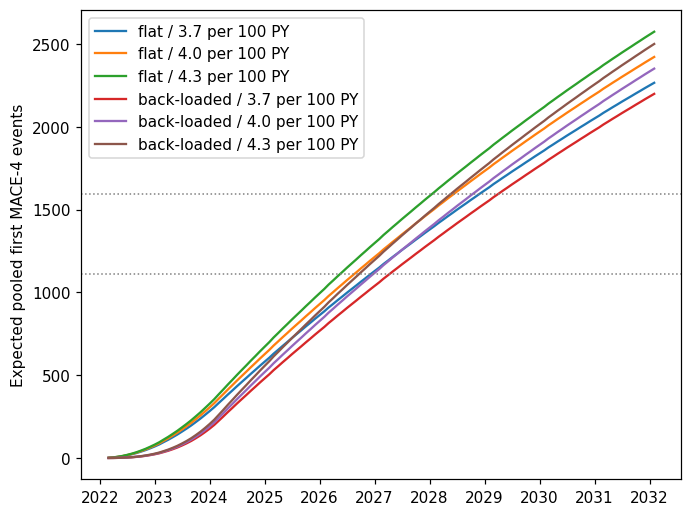

In [7]:
INTERIM_EVENTS = round(FINAL_EVENTS * INTERIM_FRACTION)
assert 0 < INTERIM_EVENTS < FINAL_EVENTS <= N
monthly_dates = pd.date_range("2022-03-01", periods=120, freq="MS")
interval_hrs = (EARLY_HR, LATE_HR)

def placebo_rates(rate_per_100, basis):
    # Divide by 100 to turn, for example, 4 per 100 years into 0.04 per year.
    rates = np.array([rate_per_100, rate_per_100 * LATE_RATE_MULTIPLIER]) / 100
    if basis == "pooled":
        # With balanced risk sets, pooled hazard is approximately placebo*(1+HR)/2.
        rates = rates * 2 / (1 + np.asarray(interval_hrs))
    return rates

def calendar(curve, rates, hrs):
    # Flat weights give equal expected enrollments per month. A linear ramp tilts enrollment later.
    weights = np.ones(enroll_months) if curve == "flat" else np.arange(1, enroll_months + 1)
    entrants = N * weights / weights.sum()
    horizon = len(monthly_dates)
    pooled = np.zeros(horizon)
    # These arrays track expected event information and log-effect contributions by look.
    log_numerator = np.zeros(horizon)
    for entry_month, cohort_size in enumerate(entrants):
        # Treat all entrants as randomized at the start of their month, half assigned to each arm.
        remaining = np.array([cohort_size / 2, cohort_size / 2])
        for month in range(entry_month, horizon):
            period = int(month - entry_month >= 12)  # index 0 through month 12, then index 1
            hazards = np.array([rates[period], rates[period] * hrs[period]])
            all_exits = hazards + exit_rate
            exit_probability = -np.expm1(-all_exits / 12)
            new_events = remaining * exit_probability * hazards / all_exits
            pooled[month] += new_events.sum()
            log_numerator[month] += new_events.sum() * math.log(hrs[period])
            remaining *= np.exp(-all_exits / 12)
    # cumsum converts monthly incident events to total first events accrued to date.
    counts = np.cumsum(pooled)
    avg_hr = np.exp(np.cumsum(log_numerator) / counts)
    return pd.DataFrame({"events": counts, "effective HR": avg_hr}, index=monthly_dates)

def at_target(projection, target):
    # True/False filter keeps months whose cumulative events have reached the target.
    reached = projection.loc[projection["events"] >= target]
    if reached.empty:
        return None, np.nan
    return reached.index[0].strftime("%Y-%m"), reached.iloc[0]["effective HR"]

curves = {}
calendar_rows = []
for shape in ["flat", "back-loaded"]:
    for rate_value in RATE_GRID:
        rate_name = f"{rate_value:.1f} per 100 PY"
        rates = placebo_rates(rate_value, RATE_BASIS)
        projected = calendar(shape, rates, interval_hrs)
        curves[(shape, rate_name)] = projected
        interim_month, interim_hr = at_target(projected, INTERIM_EVENTS)
        final_month, final_hr = at_target(projected, FINAL_EVENTS)
        calendar_rows.append([shape, rate_name, interim_month, final_month, interim_hr, final_hr])
calendar_table = pd.DataFrame(calendar_rows, columns=["Enrollment", "Rates", "Interim month",
                                                    "Full month", "Interim effective HR", "Full effective HR"])
print(calendar_table.round(3).to_string(index=False))
for label, data in curves.items():
    plt.plot(data.index, data["events"], label=" / ".join(label))
for count in [INTERIM_EVENTS, FINAL_EVENTS]:
    plt.axhline(count, color="gray", linestyle=":", linewidth=1)
plt.ylabel("Expected pooled first MACE-4 events")
plt.legend()
plt.tight_layout()
plt.show()

Dates above are the month of the expected event cutoff. Data cleaning, adjudication, a committee meeting and public disclosure can add time. Compare the output against the sponsor's timeline as a check on assumptions. The “effective HR” is an event-weighted geometric mean of interval HRs. It approximates the log-rank drift when risk sets are balanced. Strong nonproportional hazards or heavy unequal censoring warrant full patient-level simulation.

## 6 · Reconstruct the interim and full tests

The memo's 70% table uses 1,114 of 1,592 first events. An interim *observed* HR must be low enough to beat the boundary. For example, at Z=2.438, $\widehat{HR}_{crit}=\exp(-2.438/\sqrt{1114/4})\approx0.864$. If the true HR equals this cutoff, sampling variation puts roughly half the observed HRs on either side. An HR threshold alone does not tell us the chance of a win.

**Two chances to look at overlapping patients.** The final Z already contains the interim evidence. Under the canonical Normal approximation, correlation equals the square root of the information fraction. At 70%, this is 0.837. If an unusually good interim occurs, the final is also more likely to look good. We find the final boundary so the probability of *ever* crossing in the favorable direction under the null is 2.5%.

**Spending convention matters.** In the default we reproduce the memo's interim O’Brien–Fleming (OBF) Z using the Lan–DeMets OBF spending formula applied to the one-sided budget $a=0.025$: cumulative favorable alpha equals $2[1-\Phi(z_{1-a/2}/\sqrt t)]$. Convert that probability back to a favorable Z, then calibrate the final boundary. The memo reports two-sided nominal p values. Applying the OBF formula directly to 0.05 instead gives a different interim boundary. The OBF option below explicitly uses this notebook's stated convention. The strict option uses interim p=0.001 **two-sided** (Z=3.291). ORION's ≥3 SD guidance is also available as a numerical comparison. A custom fraction gives direct control over alpha spent. All PREVAIL boundaries here are scenarios.

In [8]:
def both_above(a, b, rho):
    # If first Z=x, the second is Normal with mean rho*x and SD sqrt(1-rho^2).
    # Integrate over all x above a, weighting each by its Normal probability density.
    spread = math.sqrt(1 - rho**2)
    def integrand(x):
        return norm.pdf(x) * norm.sf((b - rho * x) / spread)
    return quad(integrand, a, np.inf, epsabs=1e-10)[0]

def boundaries(first, last, alpha, family, custom_share=0.10):
    if not (0 < first < last and 0 < alpha < 1):
        raise ValueError("Use increasing event counts and a total alpha between zero and one.")
    t = first / last
    budget = alpha / 2
    if family == "OBF":
        interim_spend = 2 * norm.sf(norm.isf(budget / 2) / math.sqrt(t))
        z1 = norm.isf(interim_spend)
    elif family == "strict":
        z1 = norm.isf(0.001 / 2)
    elif family == "3 SD":
        z1 = 3.0
    elif family == "Pocock":
        z1 = norm.isf(budget * math.log1p(math.expm1(1) * t))
    elif family == "custom" and 0 < custom_share < 1:
        z1 = norm.isf(budget * custom_share)
    else:
        raise ValueError("Check spending method or custom share (strictly between 0 and 1).")
    if norm.sf(z1) >= budget:
        raise ValueError("Interim spend must leave positive alpha for final.")
    rho = math.sqrt(t)
    def excess(final_z):
        # Add early and final chances and subtract their overlap to count each trial once.
        return norm.sf(z1) + norm.sf(final_z) - both_above(z1, final_z, rho) - budget
    z2 = brentq(excess, 0, 10)
    return z1, z2

z1, z2 = boundaries(INTERIM_EVENTS, FINAL_EVENTS, TWO_SIDED_ALPHA, SPENDING, CUSTOM_SHARE)
for look, d, z in [("Interim", INTERIM_EVENTS, z1), ("Full", FINAL_EVENTS, z2)]:
    print(f"{look}: {d} events, Z {z:.3f}, nominal two-sided p {2*norm.sf(z):.5f}, "
          f"critical observed HR {math.exp(-z / math.sqrt(d/4)):.3f}")

Interim: 1114 events, Z 2.439, nominal two-sided p 0.01475, critical observed HR 0.864
Full: 1592 events, Z 2.000, nominal two-sided p 0.04551, critical observed HR 0.905


## 7 · Answer the two questions under explicit assumptions

A **true** assumed HR sets the mean Z. Each actual estimate will vary around that mean. To calculate power, shift the Normal distribution to that mean and count its area beyond the threshold. Here the large-sample SE assumes balanced risk sets. For delayed effects we can give separate *cumulative effective* HRs at the two looks. They summarize evidence up to each look. A year-2-only HR belongs in the calendar model above.

| Output | Denominator and rule |
|---|---|
| Interim MACE-4 | All modeled trials. The primary crosses at the interim look. |
| Full if collected | All modeled trials, imagined to reach full information even if the interim crossed. |
| First win at final | All modeled trials. Interim misses and final crosses. |
| Final given continuation | Only modeled trials that missed the interim primary boundary. Assumes everyone else continues and no futility stopping. |
| Win by either look | All modeled trials. The primary crosses at least once. |

The distinction matters operationally. A continuation announcement would reflect the actual committee rule. Conditioning on an interim MACE-4 miss is appropriate only if that miss causes continuation under the assumed rule.

In [9]:
def chance_of_hit(hr_interim, hr_full, first, last, z_interim, z_full):
    if min(hr_interim, hr_full) <= 0:
        raise ValueError("HRs must be positive.")
    # A true beneficial HR is below one. The minus sign makes its mean Z positive.
    mu1 = -math.log(hr_interim) * math.sqrt(first / 4)
    mu2 = -math.log(hr_full) * math.sqrt(last / 4)
    # Subtract means to express the thresholds in standard Normal units.
    a = z_interim - mu1
    b = z_full - mu2
    early = norm.sf(a)
    full = norm.sf(b)
    overlap = both_above(a, b, math.sqrt(first / last))
    first_at_final = full - overlap
    return {"Interim MACE-4": early, "Full if collected": full,
            "First win at final": first_at_final,
            "Final given continuation": first_at_final / norm.cdf(a),
            "Win by either look": early + first_at_final}

# Main scenario uses the memo's approximate HR near interim and at final (pp. 11–12).
# The weights are YOUR modeling judgments. None are estimates from NAMS patient data.
worlds = pd.DataFrame(M4_WORLDS, columns=["World", "Weight", "Interim HR", "Full HR"])
assert np.isclose(worlds["Weight"].sum(), 1) and (worlds["Weight"] >= 0).all()
results = []
for _, world in worlds.iterrows():
    result = chance_of_hit(world["Interim HR"], world["Full HR"], INTERIM_EVENTS, FINAL_EVENTS, z1, z2)
    results.append(result)
powers = pd.DataFrame(results, index=worlds["World"])
weights = worlds.set_index("World")["Weight"]
pos = powers.mul(weights, axis="index").sum()
# After a miss, less-effective worlds are more common. Divide weighted JOINT probability
# by weighted probability of continuation; averaging the conditional percentages is wrong.
pos["Final given continuation"] = pos["First win at final"] / (1 - pos["Interim MACE-4"])
powers.loc["Weighted PoS"] = pos
print((100*powers).round(1).to_string())
print("Percentages. Weights are illustrative. Outcomes assume efficacy-only stopping.")

# Carry the calendar-derived effects into the same testing calculation.
# This is a separate mechanistic scenario; it does not change the judgment weights above.
calendar_answers = []
for _, row in calendar_table.dropna().iterrows():
    ans = chance_of_hit(row["Interim effective HR"], row["Full effective HR"],
                        INTERIM_EVENTS, FINAL_EVENTS, z1, z2)
    calendar_answers.append([row["Enrollment"], row["Rates"], row["Interim month"],
                             row["Full month"], ans["Interim MACE-4"], ans["Full if collected"]])
pd.DataFrame(calendar_answers, columns=["Enrollment", "Rates", "IA cutoff", "Full cutoff",
                                       "Interim power", "Full power"]).round(3)

                Interim MACE-4  Full if collected  First win at final  Final given continuation  Win by either look
World                                                                                                              
Strong benefit            90.1               99.7                 9.6                      96.6                99.7
Memo-like                 53.1               89.3                36.3                      77.5                89.4
Weak benefit              11.0               36.8                26.3                      29.5                37.3
Null                       0.7                2.3                 1.8                       1.8                 2.5
Weighted PoS              42.1               65.2                23.3                      40.2                65.4
Percentages. Weights are illustrative. Outcomes assume efficacy-only stopping.


Enrollment,Rates,IA cutoff,Full cutoff,Interim power,Full power
flat,3.7 per 100 PY,2027-01,2028-12,0.622,0.923
flat,4.0 per 100 PY,2026-09,2028-07,0.608,0.920
flat,4.3 per 100 PY,2026-06,2028-02,0.596,0.915
back-loaded,3.7 per 100 PY,2027-05,2029-04,0.621,0.923
back-loaded,4.0 per 100 PY,2027-01,2028-11,0.608,0.919
back-loaded,4.3 per 100 PY,2026-10,2028-06,0.596,0.915


**How much does the answer depend on the unknown interim charter?** Keep the same memo-like biology, change the event fraction and alpha rule, and compare the probabilities. For the same number of accrued events and true effect, a more stringent boundary requires stronger observed evidence. A later look also gives a more precise estimate.

 Fraction  IA events   Rule  IA nominal p  IA HR cutoff  Interim chance  Full chance
     0.65       1035    OBF        0.0109        0.8536          0.4520       0.8948
     0.65       1035 strict        0.0010        0.8150          0.1937       0.9000
     0.65       1035   3 SD        0.0027        0.8299          0.2830       0.8996
     0.65       1035 Pocock        0.0375        0.8787          0.6353       0.8413
     0.65       1035 custom        0.0050        0.8399          0.3516       0.8986
     0.70       1114    OBF        0.0147        0.8641          0.5313       0.8929
     0.70       1114 strict        0.0010        0.8210          0.2196       0.9001
     0.70       1114   3 SD        0.0027        0.8355          0.3145       0.8998
     0.70       1114 Pocock        0.0395        0.8839          0.6765       0.8390
     0.70       1114 custom        0.0050        0.8452          0.3859       0.8990
     0.75       1194    OBF        0.0193        0.8733          

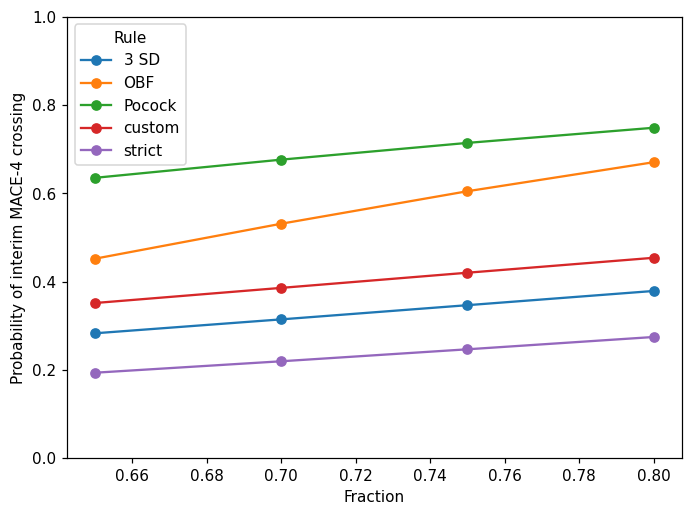

In [10]:
sensitivity = []
for fraction in [0.65, 0.70, 0.75, 0.80]:
    d = round(fraction * FINAL_EVENTS)
    for family in ["OBF", "strict", "3 SD", "Pocock", "custom"]:
        c1, c2 = boundaries(d, FINAL_EVENTS, TWO_SIDED_ALPHA, family, CUSTOM_SHARE)
        ans = chance_of_hit(0.86, 0.85, d, FINAL_EVENTS, c1, c2)
        sensitivity.append([fraction, d, family, 2*norm.sf(c1), math.exp(-c1/math.sqrt(d/4)),
                            ans["Interim MACE-4"], ans["Full if collected"]])
sens = pd.DataFrame(sensitivity, columns=["Fraction", "IA events", "Rule", "IA nominal p",
                                         "IA HR cutoff", "Interim chance", "Full chance"])
print(sens.round(4).to_string(index=False))
sens.pivot(index="Fraction", columns="Rule", values="Interim chance").plot(marker="o")
plt.ylabel("Probability of interim MACE-4 crossing")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 8 · Why the memo calls the interim a harder bet

The memo posits an extra MACE-3 hurdle. It models roughly 834 three-point events at the 70% look and 899 at 75%, and considers materially different MACE-3 effects. It quotes an optimistic HR near 0.88 at year 3 and a much weaker final HR near 0.98 in its main extrapolation. BROADWAY component estimates are imprecise. Transferring its 1.267 MACE-3/MACE-4 HR ratio or FOURIER's time trend to PREVAIL requires assumptions about component mix, population and time. A cumulative composite HR cannot be obtained by summing separate published event proportions that double-count people.

Here we allow three *hypothetical* committee screens. “Direction” accepts an estimated MACE-3 HR below one. “Both significant” requires MACE-3 and MACE-4 to pass the same interim Z threshold. The second endpoint is correlated with the first because many events and patients contribute to both. We approximate this with a user-set cross-endpoint correlation. This exercise estimates the chance of passing a numerical screen. Actual DSMB discretion, safety evidence, subgroup consistency, adjudication, mortality and futility can change the recommendation. No quantitative probability of the actual committee recommendation is identified by the disclosures.

In [11]:
# At the default 70% look this matches the memo's illustrative three-point event count.
# For other looks the count scales approximately; edit if better endpoint data emerge.
D3_IA = round(INTERIM_EVENTS * HARD_RATIO_IA)
D3_FULL = round(FINAL_EVENTS * HARD_RATIO_FULL)
assert 0 < D3_IA < D3_FULL
# Both analyses happen on the same calendar dates as MACE-4. The fraction of
# MACE-3 information may differ, so separately calibrate its hypothetical boundaries.
z3_ia, z3_full = boundaries(D3_IA, D3_FULL, TWO_SIDED_ALPHA, SPENDING, CUSTOM_SHARE)
print(f"MACE-3: {D3_IA} interim events and {D3_FULL} full events.")
print("Critical observed MACE-3 HRs:",
      round(math.exp(-z3_ia/math.sqrt(D3_IA/4)),3),
      round(math.exp(-z3_full/math.sqrt(D3_FULL/4)),3))
hard_screen = []
for name, weight, hr3_ia, hr3_full in HARD_CASES:
    result = chance_of_hit(hr3_ia, hr3_full, D3_IA, D3_FULL, z3_ia, z3_full)
    hard_screen.append([name, weight, result["Interim MACE-4"], result["Full if collected"]])
hard_screen = pd.DataFrame(hard_screen, columns=["MACE-3 world","Weight","Interim MACE-3","Full MACE-3"])
print(hard_screen.round(3).to_string(index=False))
for key in ["Interim MACE-3","Full MACE-3"]:
    print(key, "illustrative weighted PoS:", f"{sum(hard_screen.Weight*hard_screen[key]):.1%}")

MACE-3: 834 interim events and 1194 full events.
Critical observed MACE-3 HRs: 0.844 0.891
                MACE-3 world  Weight  Interim MACE-3  Full MACE-3
        Weaker hard outcomes     0.5           0.007        0.049
More favorable hard outcomes     0.5           0.276        0.728
Interim MACE-3 illustrative weighted PoS: 14.2%
Full MACE-3 illustrative weighted PoS: 38.9%


### Both endpoints and the meaning of continuation

Two correlated endpoints give several ways to win. The table below shows the chance that both endpoints cross at the same look, primary success by either look, and eventual success under a hypothetical decision rule. Under that rule, an early stop requires both endpoints. All other trials continue. At final the primary alone suffices. You can therefore answer “if they announce continuation, what happens to my final forecast?” under an explicit policy. An actual DSMB may also consider safety and futility.

A correlation of 0.80 means a favorable fluctuation in one score tends to accompany a favorable fluctuation in the other. We generate shared random noise for each period. The post-interim noise is drawn independently of the early noise. This preserves the correct within-endpoint correlations across time. The full-look cross-endpoint correlation is implied by the two information fractions. Bayesian PoS here is a weighted average of repeated-trial power over the stated possibilities. The two hard-outcome worlds share the same MACE-4 HR assumptions, so their weighted answers are conditional on that MACE-4 trajectory.

In [12]:
rng_pair = np.random.default_rng(152)
reps = 200_000
def endpoint_noise(n, correlation):
    # Start with two independent standard Normals. Reuse the first in the second
    # endpoint to create correlation while keeping the variance of each equal to one.
    four = rng_pair.normal(size=n)
    extra = rng_pair.normal(size=n)
    three = correlation * four + math.sqrt(1 - correlation**2) * extra
    return four, three

four_early, three_early = endpoint_noise(reps, ENDPOINT_CORR)
four_new, three_new = endpoint_noise(reps, ENDPOINT_CORR)
def final_noise(early, new, t):
    return math.sqrt(t)*early + math.sqrt(1-t)*new

def favorable_z(noise, hr, events):
    return noise - math.log(hr)*math.sqrt(events/4)

four_ia_win = favorable_z(four_early, PAIR_HR4[0], INTERIM_EVENTS) > z1
four_full_noise = final_noise(four_early, four_new, INTERIM_EVENTS/FINAL_EVENTS)
four_full_win = favorable_z(four_full_noise, PAIR_HR4[1], FINAL_EVENTS) > z2
three_full_noise = final_noise(three_early, three_new, D3_IA/D3_FULL)
joint_rows = []
for name, weight, hi, hf in HARD_CASES:
    three_ia_z = favorable_z(three_early, hi, D3_IA)
    three_ia_win = three_ia_z > z3_ia
    three_full_win = favorable_z(three_full_noise, hf, D3_FULL) > z3_full
    both_ia = four_ia_win & three_ia_win
    continues = ~both_ia
    # Boolean means count the fraction of simulations meeting the written rule.
    joint_rows.append([name, (four_ia_win & (three_ia_z > 0)).mean(), both_ia.mean(),
                       (four_full_win & three_full_win).mean(),
                       four_full_win[continues].mean(), (both_ia | four_full_win).mean()])
    # Cross-check the joint interim Monte Carlo result against direct integration.
    exact_joint = both_above(z1 + math.log(PAIR_HR4[0])*math.sqrt(INTERIM_EVENTS/4),
                             z3_ia + math.log(hi)*math.sqrt(D3_IA/4), ENDPOINT_CORR)
    assert abs(both_ia.mean()-exact_joint) < 5*math.sqrt(exact_joint*(1-exact_joint)/reps)+1/reps
joint_table = pd.DataFrame(joint_rows,columns=["World","M4 + favorable M3 at IA","Both cross at IA",
                           "Both cross at full if collected","Final M4 given continuation","Early both or final M4"])
print(joint_table.round(3).to_string(index=False))

                       World  M4 + favorable M3 at IA  Both cross at IA  Both cross at full if collected  Final M4 given continuation  Early both or final M4
        Weaker hard outcomes                    0.412             0.007                            0.050                        0.892                   0.893
More favorable hard outcomes                    0.531             0.257                            0.714                        0.857                   0.893


### What if the calendar date is fixed instead of the event count?

At a fixed event count and a fixed true HR, changing the background rate mostly changes **when** the analysis can occur. At a fixed date a lower rate means fewer events and a larger standard error. The next calculation gives a standalone two-sided test at the specified deadline to isolate that effect. It assumes a fixed MACE-3/MACE-4 count ratio and uses the full-horizon HRs as sensitivities. The actual trial's sequential decision still uses its prespecified rule. Pooled rates can imply higher placebo rates when treatment helps.

In [13]:
deadline_rows = []
for rate in RATE_GRID:
    for basis in ["placebo","pooled"]:
        proj = calendar("back-loaded", placebo_rates(rate, basis), interval_hrs)
        d4 = round(proj.loc[DEADLINE,"events"])
        d3 = round(d4 * HARD_RATIO_FULL)
        # Calculate a standalone favorable-tail crossing probability at this fixed date.
        def one_look(hr, d):
            expected_z = -math.log(hr)*math.sqrt(d/4)
            return norm.sf(norm.isf(TWO_SIDED_ALPHA/2)-expected_z)
        ia_date, _ = at_target(proj, INTERIM_EVENTS)
        full_date, _ = at_target(proj, FINAL_EVENTS)
        for name, weight, hi, hf in HARD_CASES:
            deadline_rows.append([rate,basis,ia_date,full_date,d4,d3,name,one_look(PAIR_HR4[1],d4),one_look(hf,d3)])
deadline_table = pd.DataFrame(deadline_rows,columns=["Rate/100 PY","Basis","IA month","Full month",
                               "M4 by deadline","M3 by deadline","M3 world","M4 power","M3 power"])
print(deadline_table.round(3).to_string(index=False))

 Rate/100 PY   Basis IA month Full month  M4 by deadline  M3 by deadline                     M3 world  M4 power  M3 power
         3.7 placebo  2027-05    2029-04            1274             956         Weaker hard outcomes     0.827     0.050
         3.7 placebo  2027-05    2029-04            1274             956 More favorable hard outcomes     0.827     0.645
         3.7  pooled  2027-01    2028-10            1373            1030         Weaker hard outcomes     0.853     0.051
         3.7  pooled  2027-01    2028-10            1373            1030 More favorable hard outcomes     0.853     0.677
         4.0 placebo  2027-01    2028-11            1370            1028         Weaker hard outcomes     0.853     0.051
         4.0 placebo  2027-01    2028-11            1370            1028 More favorable hard outcomes     0.853     0.676
         4.0  pooled  2026-10    2028-05            1475            1106         Weaker hard outcomes     0.877     0.052
         4.0  pooled  20

## 9 · See the random trials behind the probabilities

Imagine tossing a coin once per simulated trial, except the statistic is continuous and the probability changes with the assumed HR. A random Normal draw represents the estimation error of a complete look. The final statistic reuses the interim random draw and adds an independent increment for the information that arrives later. This makes the construction visible without generating 9,541 individual records for every replicate.

The following check uses a random seed for repeatability and estimates its own numerical uncertainty. Under equal hazards, the chance of ever crossing the favorable boundary should be 2.5% for total two-sided alpha 0.05. If you change the design, the checks run again.

In [14]:
rng = np.random.default_rng(20261124)
B = 100_000
noise_early = rng.normal(size=B)
new_noise = rng.normal(size=B)
rho = math.sqrt(INTERIM_EVENTS / FINAL_EVENTS)
noise_full = rho * noise_early + math.sqrt(1 - rho**2) * new_noise
def verify_world(early_hr, full_hr):
    early_z = noise_early - math.log(early_hr) * math.sqrt(INTERIM_EVENTS / 4)
    final_z = noise_full - math.log(full_hr) * math.sqrt(FINAL_EVENTS / 4)
    early_win = early_z > z1
    final_win = final_z > z2
    any_win = early_win | final_win      # Element-wise OR: at least one crossing.
    exact = chance_of_hit(early_hr, full_hr, INTERIM_EVENTS, FINAL_EVENTS, z1, z2)
    for observed, name in [(early_win, "Interim MACE-4"), (final_win, "Full if collected"),
                           (any_win, "Win by either look")]:
        theory = exact[name]
        se = math.sqrt(theory * (1 - theory) / B)
        print(f"{name}: simulated {observed.mean():.2%}, integrated {theory:.2%}, MC SE {se:.2%}")
        assert abs(observed.mean() - theory) < 5*se + 1/B
print("Memo-like scenario")
verify_world(0.86, 0.85)
print("Null check")
verify_world(1, 1)
assert abs(chance_of_hit(1, 1, INTERIM_EVENTS, FINAL_EVENTS, z1, z2)["Win by either look"]
           - TWO_SIDED_ALPHA / 2) < 1e-8

Memo-like scenario
Interim MACE-4: simulated 53.05%, integrated 53.13%, MC SE 0.16%
Full if collected: simulated 89.21%, integrated 89.29%, MC SE 0.10%
Win by either look: simulated 89.35%, integrated 89.44%, MC SE 0.10%
Null check
Interim MACE-4: simulated 0.69%, integrated 0.74%, MC SE 0.03%
Full if collected: simulated 2.25%, integrated 2.28%, MC SE 0.05%
Win by either look: simulated 2.45%, integrated 2.50%, MC SE 0.05%


## 10 · Read the results as an analyst

First read the memo-like row. It answers the question *if* the assumed HRs and event counts are right. Then read the weighted row. It allows the drug to deliver a stronger effect, a weaker effect, or no effect. The weights are deliberately visible so you can replace them with your own. The probability of a formal primary crossing can be estimated under those assumptions. Inferring the chance of an actual early stop also requires assumptions about other evidence the committee sees.

Read the timing and deadline tables together. A date later than sponsor guidance flags a mismatch among your event-rate assumption, enrollment shape and inferred target. It does not identify which assumption is wrong. The blinded year-one 4.55% figure and a multiyear rate of 3.7–4.3 per 100 person-years describe different quantities. If you believe the range applies mainly after year one, set a separate year-one hazard in placebo_rates() and retain the range for subsequent follow-up.

## 11 · Read the memo with the notebook open

| Memo pages (PDF page numbers) | What happens behind the figures | Where to inspect it |
|---|---|---|
| 1–3 | Sponsor design, reconstructed 80–90% power and event targets. Original vs amended MACE. Exact revised targets and nominal thresholds require confirmation. | Lessons 1, 3, 6 |
| 4–7 | Select comparison trials, score similarity, choose placebo event rates, model enrollment and censoring, back-solve required N or follow-up. In the calendar cell doubling N at fixed entry shape doubles expected events at each date. A subjective matching score is not a validated transport model. | Lessons 4–5 |
| 8–10 | Align calendar cutoff with time since randomization. Read pooled year-1 risk and assume an external placebo risk to infer a possible treatment trajectory. Distinguish a Kaplan–Meier percentage from events per 100 person-years. | Lessons 4–5 |
| 11–14 | Apply an assumed later/earlier HR multiplier, accumulate events, and model MACE-3 separately. The calendar cell integrates each interval and reports its event-weighted effect. The component experiment and optional MACE-3 screen show sensitivity to effect mix. | Lessons 4, 5, 8 |
| 15–17 | Compare interim spending functions and required observed HRs. A projected true HR greater than the cutoff can still win due to sampling variation. Convert thresholds into probabilities and account for correlation across endpoints and looks. | Lessons 6–9 |

**Try these exercises.** (1) Set the assumed year-one placebo risk equal to the blinded 4.55% and predict the implied HR before running. (2) Change only the enrollment shape. Explain why the date can move even when constant-HR power at a fixed event target stays the same. (3) Replace OBF with the strict p=0.001 option and examine the interim and full probabilities. (4) Move 10 percentage points of weight from the memo-like world to the null world. The weighted PoS should fall by 0.10 times the difference in those worlds' crossing probabilities. (5) Compare the chance of passing both endpoint thresholds with the chance of passing MACE-4 alone. State which one you mean whenever writing “interim PoS.”

**Evidence and reading**

- NAMS, [May 7 PREVAIL update presentation](https://ir.newamsterdampharma.com/static-files/d8d3b62b-fb6f-4e15-b115-a0f157a84c49), slides 4–6, and [May corporate update](https://ir.newamsterdampharma.com/news-releases/news-release-details/newamsterdam-pharma-provides-corporate-update-and-reports-6).
- NAMS, [August 5 Investor Day slides](https://ir.newamsterdampharma.com/static-files/04521a4a-e4b4-4825-98e9-4c7fa82cd50e). The amendment schematic and event/follow-up table are also reproduced in the supplied memo pp. 2–3.
- NAMS, [November 4 corporate presentation](https://ir.newamsterdampharma.com/static-files/e391b584-1a46-45f2-9af8-dbd415d71516), slides 25–28, [November update](https://ir.newamsterdampharma.com/news-releases/news-release-details/newamsterdam-pharma-provides-corporate-update-and-reports-8), and [Q3 Form 10-Q](https://ir.newamsterdampharma.com/static-files/1bcb83b5-769b-4306-b179-d0cf8bc589bf), risk factor on interim analyses.
- Attached ORION-4 design paper (Mafham et al.), sections on outcomes and sample size; attached mmc2 SAP version 4.3 §§4, 8; mmc4 outcomes definitions §1, §4; mmc5 Supplementary Tables 1–2. These are design sources. No inclisiran outcome estimate enters the PREVAIL scenarios.
- Attached stats(1).pdf, 17 pages. The digital source data and code underlying its embedded charts are unavailable here. This workbook independently reconstructs the calculations and labels assumptions that cannot be recovered uniquely.
- [Schoenfeld, event-based sizing](https://pubmed.ncbi.nlm.nih.gov/6354290/), [Lan and DeMets, sequential boundaries](https://doi.org/10.1093/biomet/70.3.659), [O’Hagan et al., assurance](https://doi.org/10.1002/pst.175).

## Independent forecast · Use published outcomes to predict PREVAIL

**Start here for the independent answer.** The preceding lessons reconstruct the memo for comparison. This analysis estimates both the treatment effects and event counts independently of its HR trajectories, endpoint ratio, and 1,592-event target. It conditions on hypothetical calendar cutoffs aligned with sponsor guidance. Read its date-based and fixed-target answers separately when interpreting differences.

| Input | Evidence and decision |
|---|---|
| Direct obicetrapib evidence | The peer-reviewed pooled BROADWAY/BROOKLYN study reports 12-month four-point HR 0.77 (95% CI 0.54–1.11). Its reported three-component HR 0.68 includes coronary revascularization and excludes stroke. Applying 0.68 to PREVAIL hard MACE-3 would change the endpoint. The pooled study overlaps BROADWAY, so enter it only once. [Published tables 2–3](https://doi.org/10.1016/j.jacc.2025.07.056) |
| Longer-term CETP comparator | In REVEAL, the estimated rate ratio for coronary death, MI, or presumed ischemic stroke was 0.93 (0.86–1.00). Adding coronary revascularization gave 0.93 (0.88–0.99). Follow-up was about 4 years. These secondary outcomes approximate PREVAIL's components more closely than REVEAL's primary coronary composite. The class, molecule, population, estimators and adjudication definitions still differ. [REVEAL results and definitions](https://www.ctsu.ox.ac.uk/files/research/reveal_esc_results_slides_20170829.pdf/view) |
| Relative lipid differences | REVEAL achieved about 17 mg/dL of non-HDL-C separation. In the pooled obicetrapib report the differences between reported arm changes imply about 32 mg/dL (36 minus 4). Non-HDL-C captures cholesterol carried by atherogenic particles. Scaling the outcome log effect in proportion to these differences is an extrapolation. The difference in arm medians is an approximate input. |
| MACE-3 count | In REVEAL's placebo group 1,483 people had the three-component secondary outcome and 2,214 had the four-component outcome. Use 1483/2214 as a starting ratio, applied to expected counts at both looks. Patients can qualify at different times for each endpoint. PREVAIL's actual ratio could differ. |
| Design and timing | Use PREVAIL's 9,541 participants, the user's 3.7–4.3 rate grid, a December 2026 interim cutoff, and an illustrative December 2027 full cutoff. NAMS expects a Q1 2027 DSMB recommendation. The analysis conditions on dates and imputes information. The actual protocol triggers on events. [NAMS SEC filing](https://www.sec.gov/Archives/edgar/data/1936258/000119312526446228/nams-20260930.htm) |

### Step A · Build a distribution for the true effect

On the log scale an HR of 1 is zero and a beneficial HR is negative. Dividing a published log CI width by 3.92 estimates its standard error because a 95% Normal interval spans 2 × 1.96 standard errors. Multiply the REVEAL log rate ratio by 32/17 to get a candidate full-duration obicetrapib log HR. Add a **transport SD** to reflect uncertainty in applying another trial to PREVAIL. For MACE-4, combine this candidate with the direct obicetrapib estimate using inverse-variance weights. A wider interval gets less influence. For MACE-3 use REVEAL alone. This is a simple Normal evidence model with an implicit flat initial prior on log HR. The transport SDs and duration adjustment are judgments. The pooled analysis was exploratory and its short duration motivates extra uncertainty for this use.

In [15]:
# EDIT here for the independent model. Do not change published inputs unless updating evidence.
NON_HDL_OBI, NON_HDL_REVEAL = 32, 17
REVEAL_TRANSFER_SD = 0.08       # Log-HR units. Larger = less confidence in transport.
DIRECT_TRANSFER_SD = 0.12       # Includes uncertainty about duration and populations.
INTERIM_MATURITY = 0.90         # Proportion of full log effect realized by the interim.
HARD_COUNT_RATIO = 1483 / 2214  # Approximate prevalence of three- vs four-component events.
LOOK_MONTHS = ("2026-12-01", "2027-12-01")  # Monthly index includes events through month end.
ENROLL_SHAPE = "back-loaded"
assert REVEAL_TRANSFER_SD >= 0 and DIRECT_TRANSFER_SD >= 0 and 0 < HARD_COUNT_RATIO <= 1
def log_se(lower, upper):
    return (math.log(upper) - math.log(lower)) / (2 * norm.ppf(0.975))

def independent_effect(hard, scale, transfer, include_direct=True):
    # Return the mean and SD of the uncertain FULL log HR, before drawing a trial result.
    interval = (0.86, 1.00) if hard else (0.88, 0.99)
    mean = scale * math.log(0.93)
    variance = (scale * log_se(*interval))**2 + transfer**2
    if include_direct and not hard:
        direct_mean = math.log(0.77)
        direct_var = log_se(0.54, 1.11)**2 + DIRECT_TRANSFER_SD**2
        precision = 1/variance + 1/direct_var
        mean = (mean/variance + direct_mean/direct_var) / precision
        variance = 1/precision
    return mean, math.sqrt(variance)

scale = NON_HDL_OBI / NON_HDL_REVEAL
for hard in [False, True]:
    m, sd = independent_effect(hard, scale, REVEAL_TRANSFER_SD)
    print("MACE-3" if hard else "MACE-4",
          f"median modeled full HR {math.exp(m):.3f}, predictive 95% range for true HR "
          f"{math.exp(m-1.96*sd):.3f} to {math.exp(m+1.96*sd):.3f}")

MACE-4 median modeled full HR 0.854, predictive 95% range for true HR 0.717 to 1.018
MACE-3 median modeled full HR 0.872, predictive 95% range for true HR 0.706 to 1.078


### Step B · Predict the two looks

One simulation draw has two layers of randomness. First draw a possible true treatment effect. Then draw the sampling noise of the interim and full readouts, sharing the already observed information between looks. A positive correlation between true endpoint effects represents shared biology. A separate correlation between test errors represents overlapping patients and events. Estimate the probability of success by counting wins across draws. The calendar exposure calculation uses the median MACE-4 HR to impute expected information at each date and rounds to whole events. This is a plug-in forecast conditional on an enrollment curve, with no random milestone lag. Increasing simulated replicates tightens numerical precision. It cannot resolve uncertainty about sponsor decisions.

In [16]:
TRUE_EFFECT_CORR = 0.70          # Judgment about how biological effects co-vary.
ind_rng = np.random.default_rng(481)
n_draws = 120_000
def correlated_draws(correlation):
    left = ind_rng.normal(size=n_draws)
    right = correlation * left + math.sqrt(1-correlation**2) * ind_rng.normal(size=n_draws)
    return left, right
effect_draws = correlated_draws(TRUE_EFFECT_CORR)
early_errors = correlated_draws(ENDPOINT_CORR)
later_errors = correlated_draws(ENDPOINT_CORR)

def independent_forecast(rate, scale, transfer, direct=True, shape=ENROLL_SHAPE, rule=SPENDING,
                         maturity=INTERIM_MATURITY, counts=None):
    parameters = [independent_effect(hard, scale, transfer, direct) for hard in [False, True]]
    central_hr = math.exp(parameters[0][0])
    # Use a constant full-horizon proxy HR for event accrual; the testing model
    # below permits less mature efficacy at the early look.
    placebo = rate / 100 if RATE_BASIS == "placebo" else 2*rate/100/(1+central_hr)
    exposure = calendar(shape, (placebo, placebo*LATE_RATE_MULTIPLIER), (central_hr, central_hr))
    d4 = counts if counts is not None else tuple(round(exposure.loc[month,"events"]) for month in LOOK_MONTHS)
    d3 = tuple(round(d * HARD_COUNT_RATIO) for d in d4)
    wins = []
    for j, (early, full) in enumerate([d4, d3]):
        critical_ia, critical_full = boundaries(early, full, TWO_SIDED_ALPHA, rule, CUSTOM_SHARE)
        mu, sd = parameters[j]
        # Same possible true HR underlies both looks in each virtual trial.
        beta = mu + sd * effect_draws[j]
        fraction = early/full
        final_error = math.sqrt(fraction)*early_errors[j] + math.sqrt(1-fraction)*later_errors[j]
        ia_stat = early_errors[j] - maturity * beta * math.sqrt(early/4)
        full_stat = final_error - beta * math.sqrt(full/4)
        wins.append((ia_stat > critical_ia, full_stat > critical_full))
    ia4, full4 = wins[0]
    ia3, full3 = wins[1]
    return {"rate": rate, "4 events IA": d4[0], "4 events full": d4[1],
            "3 events IA": d3[0], "3 events full": d3[1],
            "4 interim": ia4.mean(), "4 full if collected": full4.mean(),
            "3 interim": ia3.mean(), "3 full if collected": full3.mean(),
            "both at IA": (ia4 & ia3).mean(), "both at full": (full4 & full3).mean(),
            "4 final given 4 IA miss": full4[~ia4].mean()}

ind_table = pd.DataFrame([independent_forecast(r, scale, REVEAL_TRANSFER_SD) for r in RATE_GRID])
print(ind_table.round(3).to_string(index=False))

 rate  4 events IA  4 events full  3 events IA  3 events full  4 interim  4 full if collected  3 interim  3 full if collected  both at IA  both at full  4 final given 4 IA miss
  3.7         1020           1281          683            858      0.503                0.664      0.344                0.495       0.292         0.445                    0.331
  4.0         1097           1376          735            922      0.524                0.679      0.361                0.511       0.309         0.460                    0.334
  4.3         1174           1471          786            985      0.542                0.693      0.378                0.525       0.325         0.475                    0.336


### Step C · Find out what drives the answer

The no-scaling row uses the observed REVEAL outcome effect as the class anchor. The no-direct row removes the small, short obicetrapib outcomes dataset. The wider-transfer row increases uncertainty about translating REVEAL. The strict-boundary row tests interim two-sided p<0.001. The memo-event-count row keeps this independent efficacy model and substitutes the earlier assumed information sizes. This last comparison isolates the effect of design assumptions. Read each probability as conditional on the public evidence and choices in that row. The joint interim figure is a hypothetical two-endpoint crossing probability. It excludes discretionary DSMB decisions.

In [17]:
mid_rate = float(np.median(RATE_GRID))
alternatives = {
    "Reference": {},
    "No lipid scaling": {"scale": 1.0},
    "REVEAL only": {"direct": False},
    "Wider class transfer SD": {"transfer": 0.16},
    "Flat enrollment": {"shape": "flat"},
    "Equal effect at both looks": {"maturity": 1.0},
    "Strict early threshold": {"rule": "strict"},
    "Earlier memo M4 event targets": {"counts": (INTERIM_EVENTS, FINAL_EVENTS)},
}
comparison = []
for name, overrides in alternatives.items():
    args = dict(rate=mid_rate, scale=scale, transfer=REVEAL_TRANSFER_SD)
    args.update(overrides)
    comparison.append({"Model": name, **independent_forecast(**args)})
comparison = pd.DataFrame(comparison)
print(comparison[["Model","4 interim","4 full if collected","3 interim","3 full if collected",
                  "both at IA"]].round(3).to_string(index=False))
# A probability of passing both tests cannot exceed the chance of passing either alone.
assert (ind_table["both at IA"] <= ind_table[["4 interim","3 interim"]].min(axis=1)).all()

                        Model  4 interim  4 full if collected  3 interim  3 full if collected  both at IA
                    Reference      0.524                0.679      0.361                0.511       0.309
             No lipid scaling      0.310                0.458      0.182                0.298       0.142
                  REVEAL only      0.456                0.600      0.364                0.513       0.288
      Wider class transfer SD      0.584                0.695      0.401                0.505       0.350
              Flat enrollment      0.553                0.691      0.388                0.523       0.335
   Equal effect at both looks      0.579                0.679      0.412                0.511       0.358
       Strict early threshold      0.287                0.691      0.164                0.524       0.125
Earlier memo M4 event targets      0.484                0.712      0.324                0.545       0.273


**Interpretation.** Use the reference row as an independent working case, then inspect the no-scaling and strict-boundary rows before choosing a personal forecast. Non-HDL lowering supplies a plausible translation between drugs, while the extent to which it predicts clinical benefit is the most consequential judgment here. The class comparator's 0.93 effect on hard outcomes supplies evidence for some benefit and considerable uncertainty. A modest hard-endpoint benefit can still yield a much smaller interim crossing probability because fewer hard events accumulate. If the projected interim count falls below the sponsor's disclosed >950 threshold, that date/rate combination is incompatible with the trigger in expectation. Revisit timing or accrual before treating such a row as an actual interim forecast.

## Compare both forecasts

**A fair comparison needs the same question.** In this section both methods predict favorable crossings in the same direction. The memo column averages over its explicitly weighted worlds. Comparing a single favorable memo scenario with the independent model's average would mix conditional power with probability of success.

The common calculator takes (1) an endpoint, (2) an effect distribution, (3) interim and full event counts, and (4) a spending family. For the evidence model we integrate the uncertain true log HR analytically. If log HR has mean m and standard deviation s, the predictive Z statistic has mean −k·m and variance 1+k²s², where k is the square root of event information times the effect-maturity factor. The 1 represents future trial noise. The extra term represents uncertainty about the true effect. The memo's table of worlds instead gives a weighted sum of ordinary Normal tail probabilities. Both are probabilities before seeing PREVAIL's unblinded data.

In [18]:
# Reuse previously defined inputs throughout. Every comparison uses these two labels.
MEMO, EVIDENCE = "Memo scenarios", "Published evidence"
ENDPOINTS = ("MACE-4", "MACE-3")

def paired_counts(rate):
    # The calendar projection already applies the selected enrollment and rate basis.
    forecast = independent_forecast(rate, scale, REVEAL_TRANSFER_SD)
    return {
        MEMO: {"MACE-4": (INTERIM_EVENTS, FINAL_EVENTS), "MACE-3": (D3_IA, D3_FULL)},
        EVIDENCE: {"MACE-4": (forecast["4 events IA"], forecast["4 events full"]),
                   "MACE-3": (forecast["3 events IA"], forecast["3 events full"])}
    }

def marginal_chances(endpoint, effects_from, counts, rule):
    first, full = counts
    thresholds = boundaries(first, full, TWO_SIDED_ALPHA, rule, CUSTOM_SHARE)
    answers = []
    for look, (events, critical) in enumerate(zip(counts, thresholds)):
        precision = math.sqrt(events / 4)  # Approximate inverse SE of the observed log HR.
        if effects_from == MEMO:
            scenarios = M4_WORLDS if endpoint == "MACE-4" else HARD_CASES
            chance = 0.0
            for _, weight, early_hr, full_hr in scenarios:
                hr = (early_hr, full_hr)[look]
                chance += weight * norm.sf(critical + precision * math.log(hr))
        else:
            mean, sd = independent_effect(endpoint == "MACE-3", scale, REVEAL_TRANSFER_SD)
            maturity = INTERIM_MATURITY if look == 0 else 1.0
            k = precision * maturity
            chance = norm.sf((critical + k * mean) / math.sqrt(1 + (k * sd)**2))
        answers.append(chance)
    return np.array(answers)

counts_at_mid = paired_counts(mid_rate)
records = []
for endpoint in ENDPOINTS:
    for effects in (MEMO, EVIDENCE):
        for design_source in (MEMO, EVIDENCE):
            counts = counts_at_mid[design_source][endpoint]
            ia, full = marginal_chances(endpoint, effects, counts, SPENDING)
            records.append([endpoint, effects, design_source, *counts, 100*ia, 100*full])
crossed = pd.DataFrame(records, columns=["Endpoint","Effects","Counts from","IA events",
                                        "Full events","Interim %","Full %"])
print(crossed.round(1).to_string(index=False))
# The evidence branch elsewhere uses simulation. Agreement to within 1 percentage
# point checks the analytic integration against that separate implementation.
base_sim = comparison.loc[comparison.Model == "Reference"].iloc[0]
for endpoint, prefix in zip(ENDPOINTS, ["4", "3"]):
    exact = marginal_chances(endpoint,EVIDENCE,counts_at_mid[EVIDENCE][endpoint],SPENDING)
    sim = [base_sim[prefix+" interim"], base_sim[prefix+" full if collected"]]
    assert np.max(np.abs(exact-sim)) < 0.01

Endpoint            Effects        Counts from  IA events  Full events  Interim %  Full %
  MACE-4     Memo scenarios     Memo scenarios       1114         1592       42.1    65.2
  MACE-4     Memo scenarios Published evidence       1097         1376       46.2    61.6
  MACE-4 Published evidence     Memo scenarios       1114         1592       48.2    71.1
  MACE-4 Published evidence Published evidence       1097         1376       52.1    67.8
  MACE-3     Memo scenarios     Memo scenarios        834         1194       14.2    38.9
  MACE-3     Memo scenarios Published evidence        735          922       15.6    32.4
  MACE-3 Published evidence     Memo scenarios        834         1194       35.0    56.8
  MACE-3 Published evidence Published evidence        735          922       36.1    51.0


### 1 · What each approach predicts under its own assumptions

Each pair compares the scenario-weighted and evidence-weighted forecasts. The probabilities include uncertainty in the treatment effect. Read the interim and full columns separately. The corresponding exact event counts are in the table above.

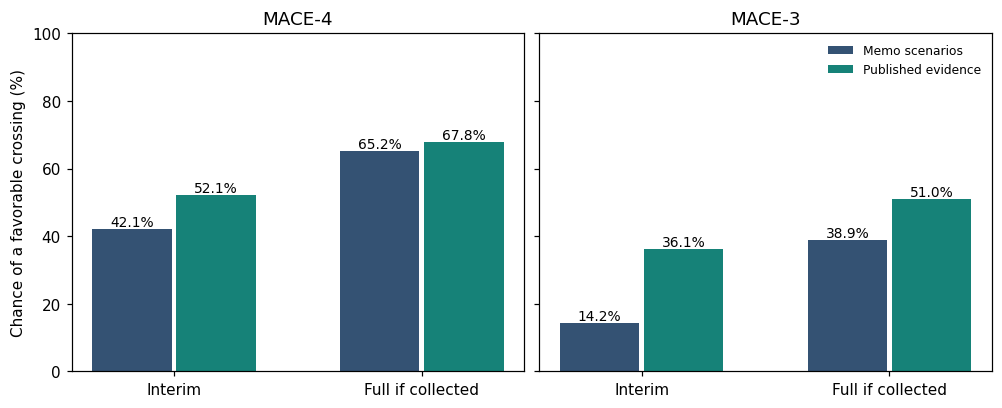

In [19]:
native = crossed[crossed["Effects"] == crossed["Counts from"]]
palette = {MEMO:"#345273", EVIDENCE:"#168278"}
fig, axes = plt.subplots(1,2, figsize=(9,3.6), sharey=True, layout="constrained")
for ax, endpoint in zip(axes, ENDPOINTS):
    for i, method in enumerate([MEMO,EVIDENCE]):
        row = native[(native.Endpoint==endpoint) & (native.Effects==method)].iloc[0]
        positions = np.arange(2) + (i-0.5)*0.34
        bars = ax.bar(positions, [row["Interim %"],row["Full %"]], width=0.32,
                      color=palette[method], label=method)
        ax.bar_label(bars, fmt="%.1f%%", fontsize=9)
    ax.set(xticks=[0,1], xticklabels=["Interim","Full if collected"], ylim=(0,100), title=endpoint)
axes[0].set_ylabel("Chance of a favorable crossing (%)")
axes[1].legend(frameon=False,fontsize=8)
plt.show()

### 2 · Which assumptions explain the gap?

Take the difference in percentage points between the two native forecasts. Switching the HR assumptions first can give a different intermediate result from switching event counts first, because power is nonlinear. Average the two possible switching orders. This yields an exact two-factor accounting of the modeled difference. The count contribution includes the change in the timing of alpha spending that follows from a different information fraction. These are model comparisons, not estimates of causal effects.

       Readout  Effect distribution  Event information  Total gap
MACE-4 interim                  6.0                4.0       10.0
   MACE-4 full                  6.0               -3.5        2.6
MACE-3 interim                 20.6                1.3       21.9
   MACE-3 full                 18.3               -6.1       12.2


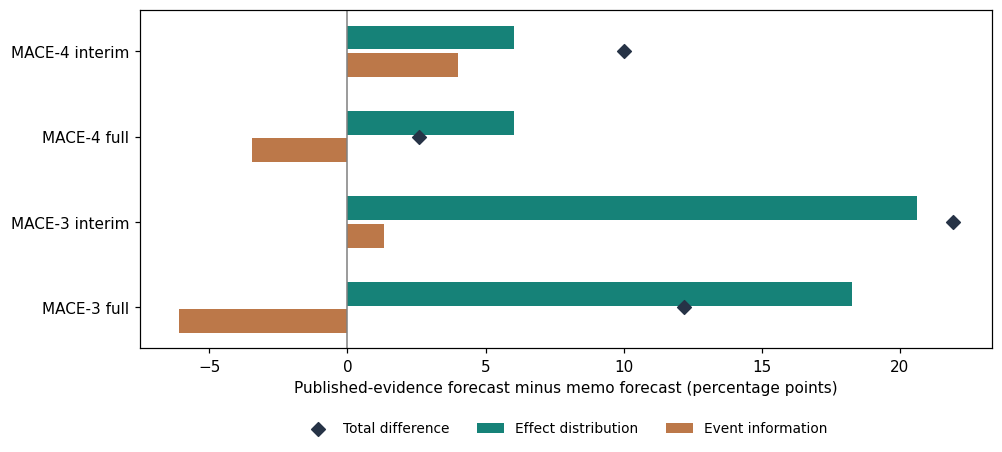

In [20]:
bridge = []
for endpoint in ENDPOINTS:
    def prediction(effect_model, count_model):
        return 100*marginal_chances(endpoint,effect_model,counts_at_mid[count_model][endpoint],SPENDING)
    mm = prediction(MEMO,MEMO)
    em = prediction(EVIDENCE,MEMO)
    me = prediction(MEMO,EVIDENCE)
    ee = prediction(EVIDENCE,EVIDENCE)
    effect_change = ((em-mm)+(ee-me))/2
    count_change = ((me-mm)+(ee-em))/2
    assert np.allclose(effect_change+count_change,ee-mm)
    for i, look in enumerate(["interim","full"]):
        bridge.append([endpoint+" "+look,effect_change[i],count_change[i],ee[i]-mm[i]])
bridge = pd.DataFrame(bridge,columns=["Readout","Effect distribution","Event information","Total gap"])
print(bridge.round(1).to_string(index=False))
fig, ax = plt.subplots(figsize=(9,4),layout="constrained")
y = np.arange(len(bridge))
for i,(field,color) in enumerate([("Effect distribution","#168278"),("Event information","#bc7849")]):
    ax.barh(y+(i-.5)*.32,bridge[field],height=.28,color=color,label=field)
ax.scatter(bridge["Total gap"],y,marker="D",s=40,color="#263346",label="Total difference",zorder=3)
ax.axvline(0,color="gray",lw=1)
ax.set(yticks=y,yticklabels=bridge.Readout,xlabel="Published-evidence forecast minus memo forecast (percentage points)")
ax.invert_yaxis()
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.18),ncol=3,frameon=False,fontsize=9)
plt.show()

### 3 · How sensitive is the comparison to the event rate and interim boundary?

The solid evidence curves translate the rate into counts at fixed dates. The dashed memo curves hold event targets fixed, so their statistical power conditional on reaching those targets stays flat as the rate changes. Their expected calendar dates can still move. Each panel imposes the same spending rule on both approaches. The strict rule uses a nominal two-sided interim p of 0.001. Changing the spending rule is a separate sensitivity from the two-factor accounting above.

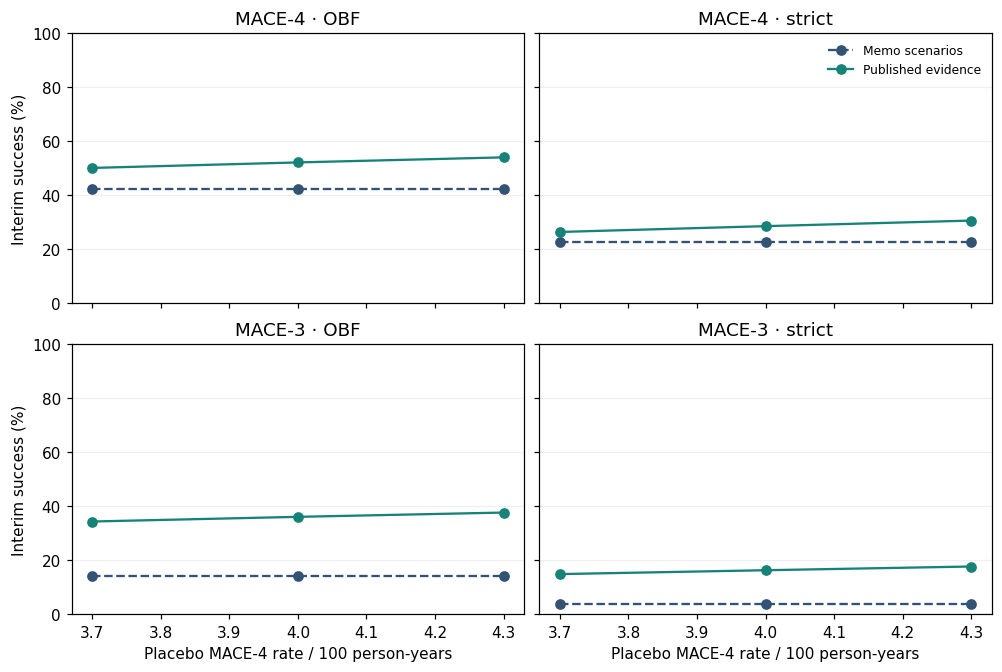

In [21]:
rules_to_plot = list(dict.fromkeys([SPENDING, "strict" if SPENDING != "strict" else "OBF"]))
grid_counts = {r:paired_counts(r) for r in sorted(RATE_GRID)}
fig, axes = plt.subplots(2,2,figsize=(9,6),sharex=True,sharey=True,layout="constrained")
for j,rule in enumerate(rules_to_plot):
    for i,endpoint in enumerate(ENDPOINTS):
        ax = axes[i,j]
        for method in [MEMO,EVIDENCE]:
            ys = [100*marginal_chances(endpoint,method,sets[method][endpoint],rule)[0]
                  for sets in grid_counts.values()]
            ax.plot(list(grid_counts),ys,marker="o",color=palette[method],label=method,
                    linestyle="--" if method==MEMO else "-")
        ax.set_title(endpoint+" · "+rule)
        ax.grid(axis="y",alpha=.2)
        ax.set_ylim(0,100)
for ax in axes[-1]: ax.set_xlabel(f"{RATE_BASIS.title()} MACE-4 rate / 100 person-years")
for ax in axes[:,0]: ax.set_ylabel("Interim success (%)")
axes[0,1].legend(frameon=False,fontsize=8)
plt.show()